In [1]:
import warnings
warnings.filterwarnings("ignore")

In [2]:
import nbimporter
from bike_sharing_data import get_bike_sharing

X_train, X_test, y_train, y_test = get_bike_sharing()

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (13903, 12)
Testing data: (3476, 12)


In [3]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

# Create polynomial regression model
poly_model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

# Train model
poly_model.fit(X_train, y_train)

print("Polynomial Regression training completed!")

Polynomial Regression training completed!


In [4]:
# Training predictions
y_train_pred_poly = poly_model.predict(X_train)

# Testing predictions
y_test_pred_poly = poly_model.predict(X_test)

In [5]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Training evaluation
train_r2_poly = r2_score(y_train, y_train_pred_poly)

# Testing evaluation
test_r2_poly = r2_score(y_test, y_test_pred_poly)

# Testing error metrics
mae_poly = mean_absolute_error(y_test, y_test_pred_poly)

mse_poly = mean_squared_error(y_test, y_test_pred_poly)

rmse_poly = np.sqrt(mse_poly)

print("Polynomial Regression Evaluation")
print("---------------------------------")
print("Training R2 :", train_r2_poly)
print("Testing R2  :", test_r2_poly)
print("MAE         :", mae_poly)
print("MSE         :", mse_poly)
print("RMSE        :", rmse_poly)

Polynomial Regression Evaluation
---------------------------------
Training R2 : 0.5519781525766865
Testing R2  : 0.5419772919048562
MAE         : 91.25342411435606
MSE         : 14503.477453270576
RMSE        : 120.43038426107664


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

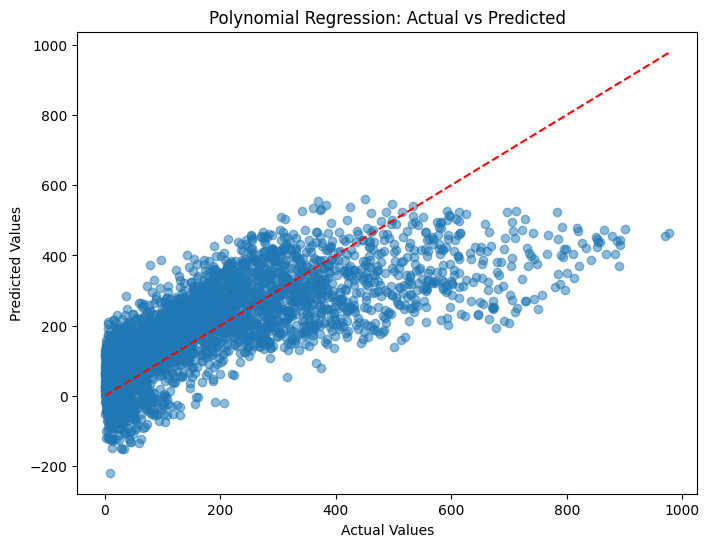

In [7]:
# Plot: Actual vs Predicted

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_test_pred_poly, alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Polynomial Regression: Actual vs Predicted")

plt.show()

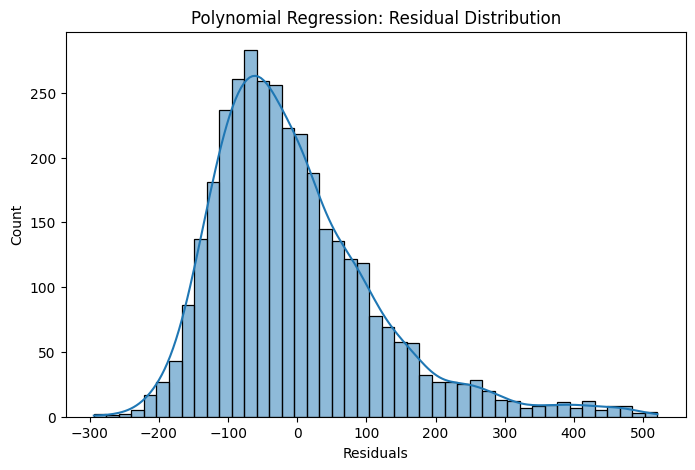

In [8]:
# Plot: Residual distribution

residuals_poly = y_test - y_test_pred_poly

plt.figure(figsize=(8, 5))

sns.histplot(residuals_poly, kde=True)

plt.xlabel("Residuals")
plt.title("Polynomial Regression: Residual Distribution")

plt.show()

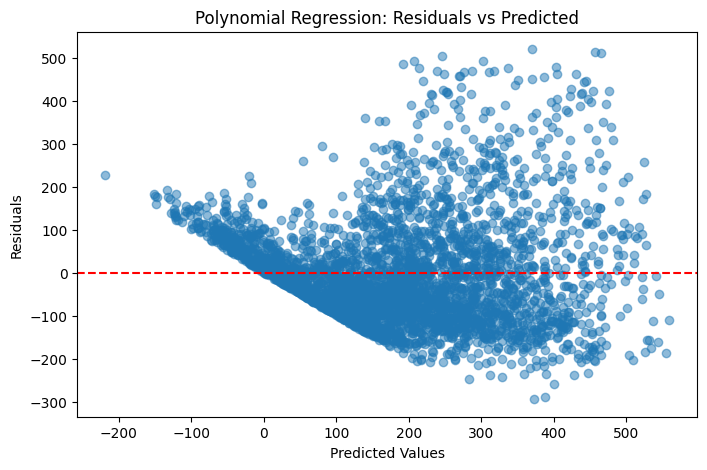

In [9]:
# Plot: Residuals vs Predicted

plt.figure(figsize=(8, 5))

plt.scatter(y_test_pred_poly, residuals_poly, alpha=0.5)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Polynomial Regression: Residuals vs Predicted")

plt.show()

In [10]:
# Degree - Model complexity
# 1	Linear Regression
# 2	Quadratic relationships
# 3	Cubic relationships
# 4	More complex relationships

poly_model_3 = make_pipeline(
    PolynomialFeatures(degree=3, include_bias=False),
    LinearRegression()
)

poly_model_3.fit(X_train, y_train)

y_pred_3 = poly_model_3.predict(X_test)

print("Degree 3 R2:", r2_score(y_test, y_pred_3))

Degree 3 R2: 0.6265519850561636
